# Data foundations: loading, quality and animation

Inspect SkillCorner data and build the representations used in every avenue.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## Load with kloppy and inspect the schema
`load_data` wraps `kloppy.skillcorner.load` and reshapes its dataframe. Here is the direct loading operation; no model is involved. Keep native metres, period keys and observed/extrapolated flags. [SkillCorner open data](https://github.com/SkillCorner/opendata), [kloppy](https://kloppy.pysport.org/).

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z
0,1,0 days 00:00:03,40,alive,1802,0.64,0.19,0.30
1,1,0 days 00:00:03.100000,41,alive,1802,1.10,0.18,0.28
2,1,0 days 00:00:03.200000,42,alive,1802,1.70,0.17,0.26
3,1,0 days 00:00:03.300000,43,alive,1802,2.36,0.16,0.24
4,1,0 days 00:00:03.400000,44,alive,1802,3.04,0.17,0.22


,rows,detected_fraction
team_id,,
871,67683,0.586573
1802,67683,0.581106


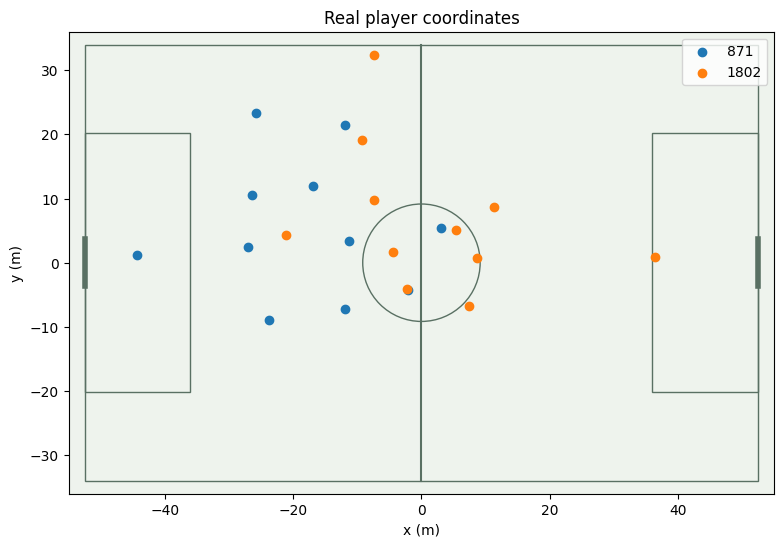

In [2]:
from kloppy import skillcorner
direct=skillcorner.load(meta_data=ROOT/'data/1925299/1925299_match.json',raw_data=ROOT/'data/1925299/1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
display(direct.to_df().iloc[:5,:8])
display(tracking.groupby('team_id').agg(rows=('player_id','size'),detected_fraction=('is_detected','mean')))
fig,ax=plt.subplots(figsize=(10,6));pitch(ax)
for team,g in snapshot.groupby('team_id'):
    ax.scatter(g.x,g.y,label=str(team))
ax.legend();ax.set_title('Real player coordinates');plt.show()

## Animate coordinates directly
Use a short sequence with complete player coverage and consecutive frames. The output is embedded HTML; a moving point does not establish that every coordinate was directly observed by the camera.

In [3]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
coverage=observed.groupby('frame_id').size()
available=coverage[coverage.eq(22)].index.to_numpy()
start=next(int(f) for f in available if all(f+j in available for j in range(30)))
clip=observed[observed.frame_id.between(start,start+29)]
fig,ax=plt.subplots(figsize=(8,5));pitch(ax)
scat=ax.scatter([],[],s=60)
def update(i):
    g=clip[clip.frame_id.eq(start+i)]
    scat.set_offsets(g[['x','y']].to_numpy())
    scat.set_color(np.where(g.team_id.eq(1802),'#e87524','#7761be'))
    ax.set_title(f'Frame {start+i}');return (scat,)
animation=FuncAnimation(fig,update,frames=30,interval=100,blit=False)
plt.close(fig);display(HTML(animation.to_jshtml()))

## Checks and interpretation
Inspect missing coordinates, identity continuity, timestamps and visibility before modeling. Retain extrapolated positions as an explicit quality feature rather than silently treating them as measured observations. All following notebooks use a bounded sample, never a full-match workload estimate.